In [67]:
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt

from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression

In [68]:
df = pd.read_csv("temperature_electricity_polynomial_regression.csv")
df.head()

,temperature_c,daily_electricity_kwh
0,41.56,183.76
1,40.72,162.43
2,9.15,93.17
3,23.07,56.74
4,21.03,55.71


In [69]:
df.isnull().sum()

temperature_c            0
daily_electricity_kwh    0
dtype: int64

In [70]:
len(df)

240

In [71]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 2 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   temperature_c          240 non-null    float64
 1   daily_electricity_kwh  240 non-null    float64
dtypes: float64(2)
memory usage: 3.9 KB


In [72]:
X = df[["temperature_c"]]
y = df["daily_electricity_kwh"]

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20, random_state=42)

<Axes: xlabel='temperature_c', ylabel='daily_electricity_kwh'>

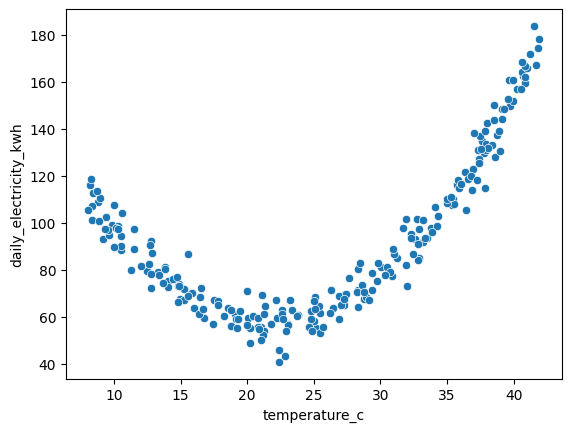

In [73]:
sns.scatterplot(data=df, x= "temperature_c", y = "daily_electricity_kwh")

In [74]:
def make_poly_model(degree):
    return Pipeline([
        ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
        ("scaler", StandardScaler()),
        ("lin_reg", LinearRegression())
    ])

In [75]:
pipeline = make_poly_model(degree=1)

param_grid = {
    "poly__degree" : list(range(1,11))
}

In [76]:
grid = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv = 5,
    scoring="neg_root_mean_squared_error"
    
)

In [77]:
grid.fit(X_train, y_train)
print("Best Degree: ", grid.best_params_["poly__degree"])
print("Best CV RMSE: ", round(-grid.best_score_,3))

Best Degree:  3
Best CV RMSE:  6.062


In [78]:
# R2 = r2_score(y_test, y_pred)
# print("R2 Score: ", R2)
# MSE = mean_squared_error(y_test, y_pred)
# print("MSE: ", MSE)

In [79]:
best_model = grid.best_estimator_

y_pred_best = best_model.predict(X_test)
print("R2 Score: ", r2_score(y_test, y_pred_best))

R2 Score:  0.9736394698154857


In [80]:
df.head()

,temperature_c,daily_electricity_kwh
0,41.56,183.76
1,40.72,162.43
2,9.15,93.17
3,23.07,56.74
4,21.03,55.71


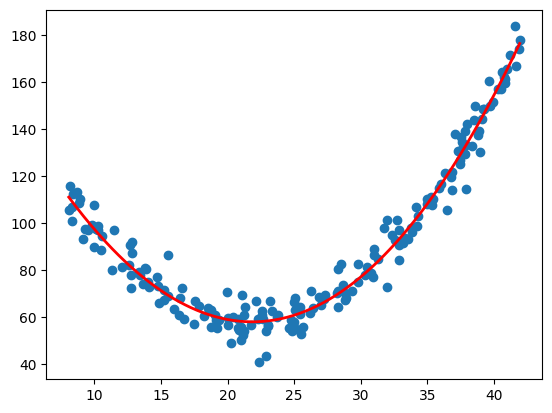

In [81]:
plt.scatter(X_train, y=y_train)
x_range = pd.DataFrame({"temperature_c": np.linspace(X["temperature_c"].min(), X["temperature_c"].max(), 300)})
plt.plot(x_range, best_model.predict(x_range), color="red", linewidth=2, label="Straight line")

In [ ]:
# RandomSearchCV -----> use n_iter parameter for give number of iterations